# Pipelines Module Demonstration

This notebook demonstrates the high-level workflow pipelines provided by `lab_math_tools.pipelines`:
- **`linear_fit_pipeline`**: Complete linear regression workflow: automatic ordinary least-squares fit, measurement plotting (with error bars support), overlay of the regression line, and structured Excel reporting.
- **`custom_fit_pipeline`**: Non-linear curve fitting pipeline: supports single or multiple candidate models, side-by-side 1×2 subplots (fitted curves on the left, residuals comparison on the right), goodness-of-fit model ranking, and multi-sheet Excel reporting.


In [1]:
# Imports & Configuration
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from lab_math_tools.pipelines import (
    linear_fit_pipeline,
    custom_fit_pipeline,
    LinearPipelineResult,
    CustomPipelineResult,
)

RNG = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 120


---
## 1. Automatic Linear Fit Pipeline

`linear_fit_pipeline` automates:
1. Fitting $y = a_0 + a_1 x$ via ordinary least squares.
2. Computing parameter standard errors $\sigma_p = \sqrt{\text{diag}(M_{\text{cov}})}$.
3. Plotting measurements (with optional symmetric $x$ and $y$ error bars).
4. Overlaying the fitted regression line labeled with parameter values and $R^2$.
5. Saving results to an Excel spreadsheet (`.xlsx`).


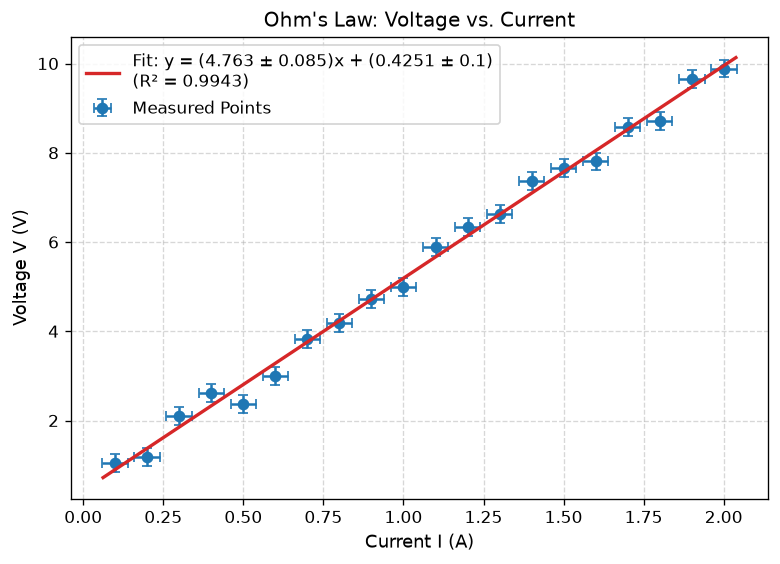

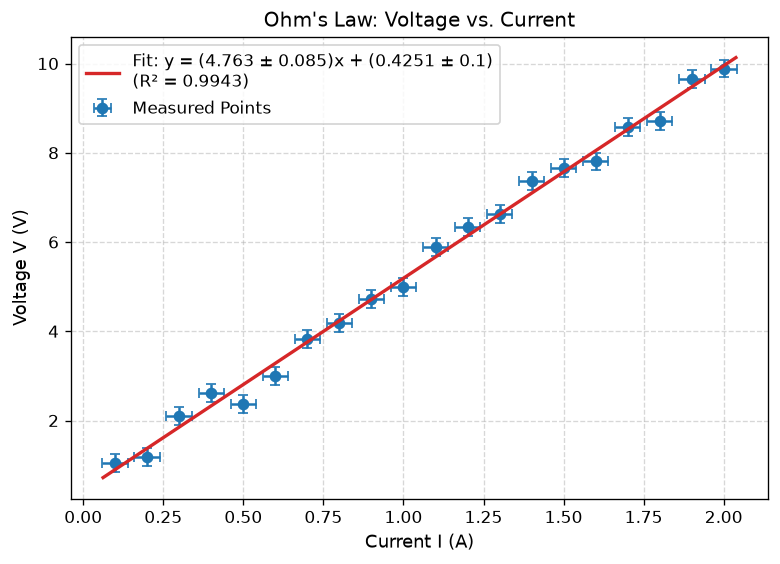

In [2]:
# Generate synthetic lab data: Ohm's law V = I * R + offset
# True values: R = 4.7 Ohm, V_offset = 0.5 V
v_i = np.linspace(0.1, 2.0, 20)  # Current (A)
v_v = 4.7 * v_i + 0.5 + RNG.normal(0, 0.25, len(v_i))  # Voltage (V)

# Experimental measurement uncertainties
v_i_err = np.full_like(v_i, 0.04)   # ±0.04 A
v_v_err = np.full_like(v_v, 0.20)   # ±0.20 V

excel_linear_file = "linear_fit_report.xlsx"

# Run linear fit pipeline
lin_result = linear_fit_pipeline(
    v_x=v_i,
    v_y=v_v,
    v_x_err=v_i_err,
    v_y_err=v_v_err,
    title="Ohm's Law: Voltage vs. Current",
    xlabel="Current I (A)",
    ylabel="Voltage V (V)",
    data_label="Measured Points",
    excel_path=excel_linear_file,
    show=False,
)

lin_result.fig


In [3]:
# Inspect fitted parameters and uncertainties
print("=== Fit Summary ===")
print(lin_result.fit_result.summary())
print(f"\nStandard Errors: Intercept = ±{lin_result.v_stderr[0]:.4f}, Slope = ±{lin_result.v_stderr[1]:.4f}")

# Read and display the generated Excel report
excel = pd.ExcelFile(excel_linear_file)
print(f"\nGenerated Excel Sheets: {excel.sheet_names}")
df_params = pd.read_excel(excel_linear_file, sheet_name="Parameters")
print("\n--- Parameters Sheet ---")
print(df_params.to_string(index=False))

df_metrics = pd.read_excel(excel_linear_file, sheet_name="Metrics")
print("\n--- Metrics Sheet ---")
print(df_metrics.to_string(index=False))


=== Fit Summary ===
Model: linear
Parameters:
  p[0] = 0.425133
  p[1] = 4.76346
Metrics:
  mse = 0.0436202
  rmse = 0.208855
  mae = 0.177313
  r2 = 0.994252
  std_residuals = 0.208855
  r2_adj = 0.993575

Standard Errors: Intercept = ±0.1023, Slope = ±0.0854

Generated Excel Sheets: ['Parameters', 'Metrics']

--- Parameters Sheet ---
Parameter    Value  Std_Error
intercept 0.425133   0.102268
    slope 4.763461   0.085371

--- Metrics Sheet ---
       Metric    Value
          mse 0.043620
         rmse 0.208855
          mae 0.177313
           r2 0.994252
std_residuals 0.208855
       r2_adj 0.993575


---
## 2. Custom Fit Pipeline (Single Model) with Residuals Subplot

`custom_fit_pipeline` fits any custom scalar function $s_f(v_x)$ and generates a **1×2 side-by-side visualization**:
- **Left subplot**: Measurements (with optional error bars) and the smooth fitted model curve.
- **Right subplot**: Stem plot of residuals $(y - \hat{y})$ against sample index with a $y=0$ baseline.


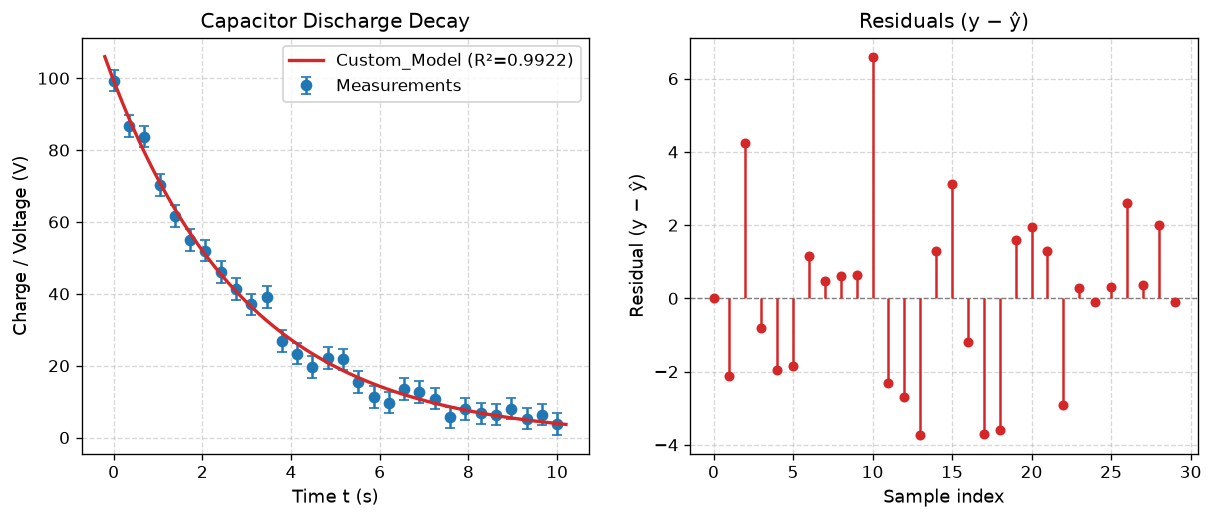

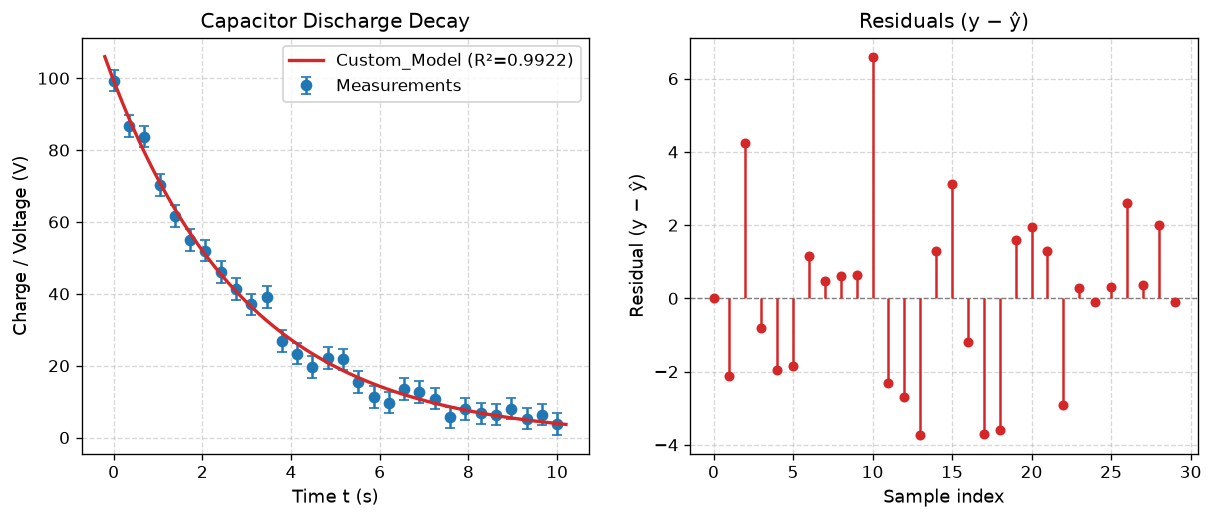

In [4]:
# Radioactive / capacitor decay data: N(t) = N0 * exp(-t / tau)
# Model convention: v_x[0] is time t, v_x[1] is N0, v_x[2] is tau
def s_f_decay(v_x: np.ndarray) -> float:
    t = v_x[0]
    n0 = v_x[1]
    tau = v_x[2]
    return float(n0 * np.exp(-t / tau))

v_t = np.linspace(0.0, 10.0, 30)
v_counts = 100.0 * np.exp(-v_t / 3.0) + RNG.normal(0, 3.5, len(v_t))
v_counts_err = np.full_like(v_counts, 3.0)

excel_single_file = "single_custom_fit_report.xlsx"

# Run custom fit pipeline with initial parameter guess [N0=90, tau=2.5]
custom_res_single = custom_fit_pipeline(
    v_x=v_t,
    v_y=v_counts,
    v_y_err=v_counts_err,
    s_f=s_f_decay,
    v_p0=[90.0, 2.5],
    title="Capacitor Discharge Decay",
    xlabel="Time t (s)",
    ylabel="Charge / Voltage (V)",
    excel_path=excel_single_file,
    show=False,
)

custom_res_single.fig


In [5]:
# Display parameter estimates and metrics
fit_res = custom_res_single.d_results["Custom_Model"]
stderrs = custom_res_single.d_stderr["Custom_Model"]

print(f"Fitted N0  = {fit_res.v_params[0]:.2f} ± {stderrs[0]:.2f}")
print(f"Fitted tau = {fit_res.v_params[1]:.2f} ± {stderrs[1]:.2f}")
print(f"R² = {fit_res.metrics['r2']:.4f}, RMSE = {fit_res.metrics['rmse']:.3f}")


Fitted N0  = 99.35 ± 1.49
Fitted tau = 3.09 ± 0.07
R² = 0.9922, RMSE = 2.380


---
## 3. Multi-Model Comparison Pipeline

When analyzing lab data, multiple theoretical models are often evaluated to determine which best describes the underlying physics.

`custom_fit_pipeline` supports comparing multiple candidate models via dictionary (`d_s_f`):
- All fitted curves are overlaid on the measurements with distinct colors.
- Residuals for all models are plotted together on the right subplot to visually detect systematic trends or model bias.
- A **Model Comparison Table** is generated and exported to Excel, ranking all models by $R^2$, $R^2_{\text{adj}}$, and $\text{RMSE}$.


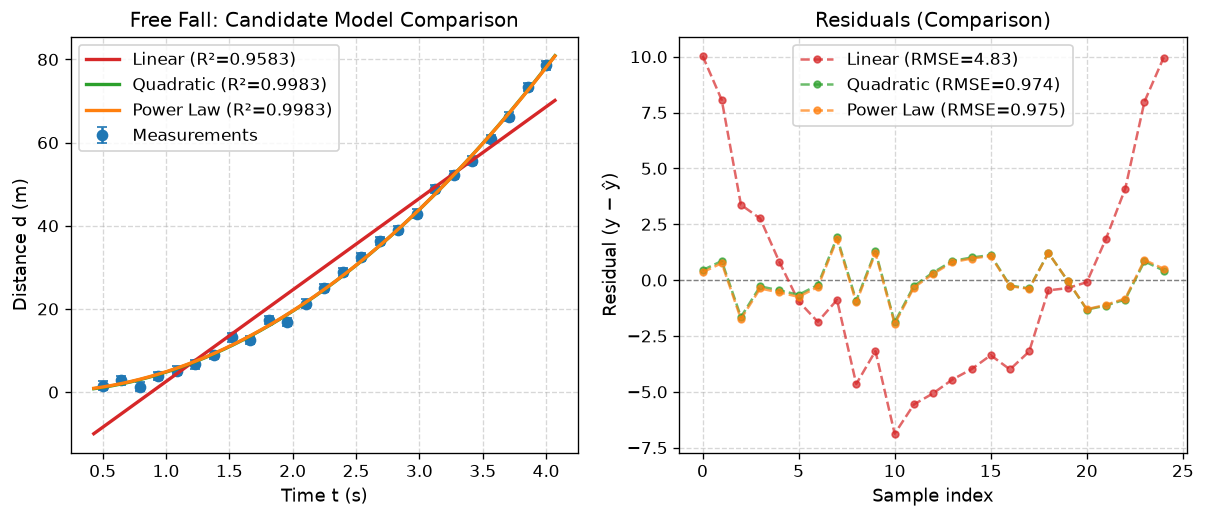

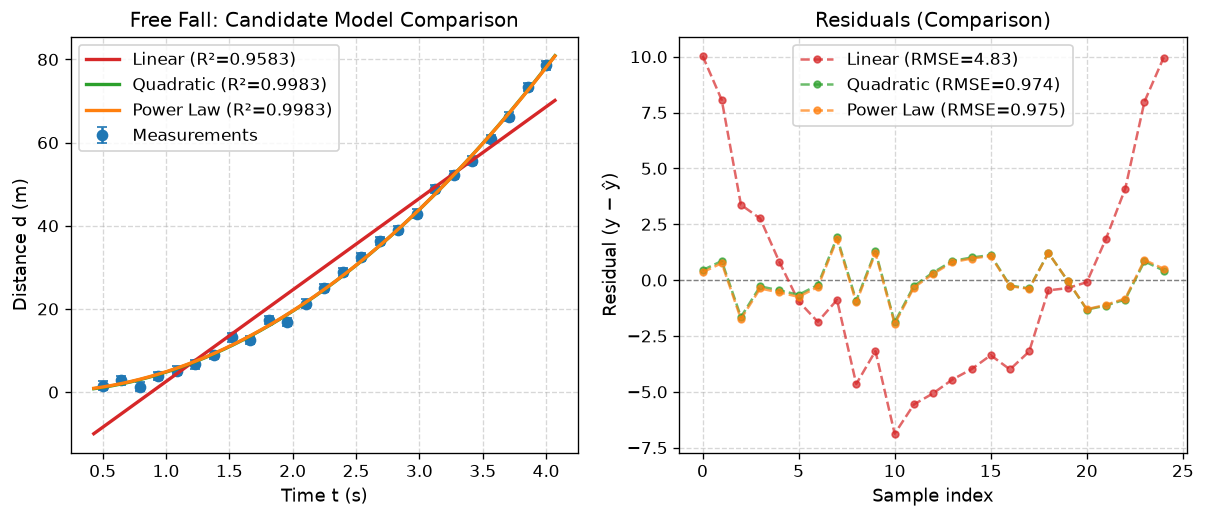

In [6]:
# Physics experiment: Free-fall distance vs time
# True physics: d = 0.5 * g * t^2  (quadratic)
v_time = np.linspace(0.5, 4.0, 25)
v_dist = 0.5 * 9.8 * (v_time ** 2) + RNG.normal(0, 1.2, len(v_time))
v_dist_err = np.full_like(v_dist, 1.0)

# Candidate 1: Linear model d(t) = a + b*t
def s_f_linear(v_x: np.ndarray) -> float:
    return float(v_x[1] + v_x[2] * v_x[0])

# Candidate 2: Quadratic model d(t) = a + 0.5*g*t^2
def s_f_quadratic(v_x: np.ndarray) -> float:
    return float(v_x[1] + 0.5 * v_x[2] * (v_x[0] ** 2))

# Candidate 3: Power law d(t) = a * t^b
def s_f_power(v_x: np.ndarray) -> float:
    return float(v_x[1] * (v_x[0] ** v_x[2]))

candidate_models = {
    "Linear": s_f_linear,
    "Quadratic": s_f_quadratic,
    "Power Law": s_f_power,
}

initial_guesses = {
    "Linear": [0.0, 10.0],
    "Quadratic": [0.0, 9.8],
    "Power Law": [4.0, 2.0],
}

excel_comp_file = "model_comparison_report.xlsx"

# Run multi-model comparison pipeline
comp_result = custom_fit_pipeline(
    v_x=v_time,
    v_y=v_dist,
    v_y_err=v_dist_err,
    d_s_f=candidate_models,
    d_v_p0=initial_guesses,
    title="Free Fall: Candidate Model Comparison",
    xlabel="Time t (s)",
    ylabel="Distance d (m)",
    excel_path=excel_comp_file,
    show=False,
)

comp_result.fig


In [7]:
# Display the automated goodness-of-fit comparison table
print("=== Model Comparison Metrics ===")
print(comp_result.df_metrics_comparison.to_string(index=False))

# Load Excel report
excel_comp = pd.ExcelFile(excel_comp_file)
print(f"\nExcel sheets generated: {excel_comp.sheet_names}")
df_comp_sheet = pd.read_excel(excel_comp_file, sheet_name="Model_Comparison")
print("\n--- Model Comparison Sheet ---")
print(df_comp_sheet.to_string(index=False))

df_params_sheet = pd.read_excel(excel_comp_file, sheet_name="Parameters")
print("\n--- Parameters Sheet ---")
print(df_params_sheet.to_string(index=False))


=== Model Comparison Metrics ===
    Model       mse     rmse      mae       r2  std_residuals   r2_adj
   Linear 23.318019 4.828874 3.914835 0.958339       4.828874 0.954552
Quadratic  0.947835 0.973568 0.824674 0.998307       0.973568 0.998153
Power Law  0.950982 0.975183 0.833077 0.998301       0.974281 0.998146

Excel sheets generated: ['Model_Comparison', 'Parameters']

--- Model Comparison Sheet ---
    Model       mse     rmse      mae       r2  std_residuals   r2_adj
   Linear 23.318019 4.828874 3.914835 0.958339       4.828874 0.954552
Quadratic  0.947835 0.973568 0.824674 0.998307       0.973568 0.998153
Power Law  0.950982 0.975183 0.833077 0.998301       0.974281 0.998146

--- Parameters Sheet ---
    Model Parameter      Value  Std_Error
   Linear      p[0] -19.482709   2.377989
   Linear      p[1]  22.023254   0.957466
Quadratic      p[0]  -0.093215   0.329106
Quadratic      p[1]   9.779785   0.083988
Power Law      p[0]   4.890218   0.158845
Power Law      p[1]   1.99835